# Paso 2 · CNN + Transformer por época + Transformer entre épocas, con canales variables

**Proyecto de grado — Maestría en Inteligencia Artificial (MAIA), Universidad de los Andes · Grupo 3**

Segundo modelo base del sistema. A diferencia del paso 1, esta red no recibe rasgos: recibe **la señal cruda** (3000 muestras por época y canal) y sirve para las 12 combinaciones de canales.

La idea imita lo que hace un técnico de sueño:

```
80 épocas seguidas (40 min) × canales presentes
  │
  CNN ─────────────────────── reconoce formas dentro de cada época (husos, complejos K, ondas lentas)
  Transformer por época ───── relaciona los momentos de la época entre sí → 1 vector de 128 por época y canal
  Fusión ──────────────────── promedia los canales presentes y agrega cuáles están
  Transformer entre épocas ── cada época mira a las otras 79, las de antes y las de después
  │
  W / N1 / N2 / N3 / REM para cada una de las 80 épocas
```

**Variante experimental.** En la versión original, el último nivel es una BiLSTM sobre 20 épocas (10 min). Aquí se reemplaza por 2 capas de Transformer sobre 80 épocas (40 min), para que cada época vea buena parte de un ciclo de sueño. El resto de la red, los datos y el entrenamiento no cambian. Las 2 capas tienen casi los mismos parámetros que la BiLSTM, así que la diferencia se debe al contexto y no al tamaño.

| Sección | Contenido |
|---|---|
| 1 | Configuración |
| 2 | Preprocesamiento de los 4 canales |
| 3 | La arquitectura, pieza por pieza |
| 4 | Cómo se arman los datos para entrenar |
| 5 | Entrenamiento |
| 6 | Predicción de una noche |
| 7 | Los 6 entrenamientos (5 folds + final) en paralelo |
| 8 | Resultados |
| 9 | Matrices de confusión |

Necesita una GPU NVIDIA: en una A100 de Colab tarda ~2–2.5 h. En CPU funciona, pero tardaría días.

## 1. Configuración

En Colab, el repositorio debe estar en Google Drive (`MyDrive/repo`), con los datos en `repo/data/`. Los EDF se copian al disco de la máquina, porque leerlos desde Drive es lento. Se copia cada archivo que falte o que tenga un tamaño distinto del de Drive, así que una copia interrumpida se completa al volver a correr la celda. Deben ser 306 archivos (153 noches). Las noches preprocesadas también quedan en el disco de la máquina.

Las predicciones de cada entrenamiento se guardan en `paso_3_meta_model/entradas/paso_2_transformer/`, que es lo que lee el paso 3 con `PASO_2 = "paso_2_transformer"`. Es una carpeta distinta de la de la versión original (`paso_2_deep_model/`), así que las dos pueden convivir en el mismo Drive. Las noches preprocesadas sí son las mismas. Si Colab se desconecta, al volver a correr el notebook se saltan los entrenamientos que ya terminaron.

Colab no trae MNE (para leer los EDF): la celda lo instala si hace falta.

La variable de entorno de la primera línea hace que PyTorch pregunte si hay GPU **sin inicializarla**. Esto es necesario para entrenar en paralelo (sección 7).

In [1]:
from pathlib import Path
fs = sorted(Path("/content/drive/MyDrive/repo/data/sleep-cassette").glob("SC4*.edf"))
print(len(fs), "archivos,", f"{sum(f.stat().st_size for f in fs):,}", "bytes")


import shutil
shutil.rmtree("/content/sleep-cassette", ignore_errors=True)
shutil.rmtree("/content/noches", ignore_errors=True)


0 archivos, 0 bytes


In [2]:
import os
os.environ["PYTORCH_NVML_BASED_CUDA_CHECK"] = "1"

import copy
import csv
import json
import multiprocessing as mp
import shutil
import sys
import time
import warnings
from pathlib import Path

if "google.colab" in sys.modules:   # Colab no trae MNE
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mne==1.12.1"], check=True)

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import clear_output, display
from joblib import Parallel, delayed
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, f1_score
from torch import nn

warnings.filterwarnings("ignore")
mne.set_log_level("ERROR")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ = Path("/content/drive/MyDrive/repo")
else:
    RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "particiones.json").exists())

DATA = RAIZ / "data"
EDF = DATA / "sleep-cassette"
if EN_COLAB:
    local = Path("/content/sleep-cassette")
    local.mkdir(exist_ok=True)
    edfs = sorted(EDF.glob("SC4*.edf"))
    assert len(edfs) == 306, f"en {EDF} hay {len(edfs)} EDF y deben ser 306: ¿terminó de subir a Drive?"
    for src in edfs:
        dst = local / src.name
        if not dst.exists() or dst.stat().st_size != src.stat().st_size:
            shutil.copy2(src, dst)
    EDF = local
NOCHES = Path("/content/noches") if EN_COLAB else DATA / "procesados" / "paso_2" / "noches"
LOGS = DATA / "procesados" / "paso_2_transformer" / "logs"
SALIDA = RAIZ / "paso_3_meta_model" / "entradas" / "paso_2_transformer"

SEED = 42
PRUEBA = False      # True: 6 noches y 2 pasadas, solo para comprobar que todo corre
EN_PARALELO = 6     # entrenamientos a la vez en la GPU; 1 = uno tras otro, en este mismo proceso
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
if PRUEBA:
    LOGS, SALIDA = LOGS.with_name("logs_prueba"), SALIDA.with_name("paso_2_transformer_prueba")
for d in (NOCHES, LOGS, SALIDA):
    d.mkdir(parents=True, exist_ok=True)

particion = json.loads((RAIZ / "particiones.json").read_text())
CONFIGS = {k: tuple(v) for k, v in particion["combinaciones"].items()}
MODALIDADES = ("fpz", "pz", "eog", "emg")
ESTADIOS = ["W", "N1", "N2", "N3", "REM"]


def mascara(cfg):
    """[fpz, pz, eog, emg] -> True si el canal está en la combinación."""
    return [m in CONFIGS[cfg] for m in MODALIDADES]


print(f"Colab: {EN_COLAB} | dispositivo para entrenar: {DISPOSITIVO} | {len(CONFIGS)} combinaciones")

Mounted at /content/drive
Colab: True | dispositivo para entrenar: cuda | 12 combinaciones


## 2. Preprocesamiento de los 4 canales

Se usan las mismas épocas que en el resto del proyecto: la ventana de sueño con 30 min de vigilia a cada lado, sin las épocas `?` ni de movimiento. Son 195 469.

- **Fpz-Cz, Pz-Oz y EOG (100 Hz):** filtro pasa-banda de 0.3 a 35 Hz (FIR, ventana de Hamming) sobre el registro completo y **z-score por época**. Cada época queda como 3000 números con media 0 y desviación 1, y se guarda en float16 para ahorrar memoria.
- **EMG:** viene a 1 Hz (30 valores por época). Se toma log(1 + µV) y un z-score robusto por noche (mediana e IQR), porque su escala cambia mucho de una persona a otra.

Cada noche se guarda en un `.npz` (~3.3 GB en total). Tarda unos 5 minutos.

In [3]:
STAGE_MAP = {"Sleep stage W": 0, "Sleep stage 1": 1, "Sleep stage 2": 2,
             "Sleep stage 3": 3, "Sleep stage 4": 3, "Sleep stage R": 4}
UNKNOWN = -1
FS, EPOCH = 100, 30
SPE = FS * EPOCH   # muestras por época
CHANNELS = {"fpz": "EEG Fpz-Cz", "pz": "EEG Pz-Oz", "eog": "EOG horizontal", "emg": "EMG submental"}


def list_nights(raw_dir):
    psgs = {p.name[:6]: p for p in Path(raw_dir).glob("SC4*-PSG.edf")}
    hyps = {p.name[:6]: p for p in Path(raw_dir).glob("SC4*-Hypnogram.edf")}
    return [(k, psgs[k], hyps[k]) for k in sorted(psgs) if k in hyps]


def hypnogram_labels(hyp_path, n_epochs, epoch_sec=EPOCH):
    ann = mne.read_annotations(hyp_path)
    labels = np.full(n_epochs, UNKNOWN, dtype=np.int64)
    for onset, duration, desc in zip(ann.onset, ann.duration, ann.description):
        start = int(round(onset / epoch_sec))
        stop = min(start + int(round(duration / epoch_sec)), n_epochs)
        labels[start:stop] = STAGE_MAP.get(desc, UNKNOWN)
    return labels


def sleep_window(labels, wake_margin_min=30, epoch_sec=EPOCH):
    sleep_idx = np.where(labels > 0)[0]
    margin = int(wake_margin_min * 60 / epoch_sec)
    return max(sleep_idx[0] - margin, 0), min(sleep_idx[-1] + margin, len(labels) - 1)


def zscore(x):
    return ((x - x.mean(1, keepdims=True)) / (x.std(1, keepdims=True) + 1e-8)).astype(np.float32)


def load_night(psg_path, hyp_path):
    """fpz, pz, eog: (n, 3000) float16 · emg: (n, 30) · y: (n,) · pos: posición de cada época en el registro."""
    raw = mne.io.read_raw_edf(psg_path, include=list(CHANNELS.values()), preload=True, verbose="error")
    data = {k: raw.get_data(picks=[ch])[0] for k, ch in CHANNELS.items()}
    n = len(data["fpz"]) // SPE
    labels = hypnogram_labels(hyp_path, n, EPOCH)
    first, last = sleep_window(labels, 30, EPOCH)
    keep = np.arange(first, last + 1)
    keep = keep[labels[keep] != UNKNOWN]

    out = {"y": labels[keep].astype(np.int64), "pos": keep}
    for k in ("fpz", "pz", "eog"):
        sig = mne.filter.filter_data(data[k], FS, 0.3, 35.0, method="fir", fir_window="hamming", verbose="error")
        out[k] = zscore(sig[: n * SPE].reshape(n, SPE)[keep]).astype(np.float16)
    # El EMG viene a 1 Hz y MNE lo interpola a 100 Hz: cada 100 muestras está el valor original
    emg = np.log1p(np.abs(data["emg"][: n * SPE: FS].reshape(n, EPOCH)[keep]) * 1e6)
    med = np.median(emg)
    iqr = np.subtract(*np.percentile(emg, [75, 25])) or 1.0
    out["emg"] = ((emg - med) / iqr).astype(np.float32)
    return out


def preprocess(job):
    nid, psg, hyp = job
    try:
        night = load_night(psg, hyp)
    except Exception as e:
        raise RuntimeError(f"no se pudo leer {psg.name} / {hyp.name} ({psg.stat().st_size:,} bytes): {e}") from e
    np.savez(NOCHES / f"{nid}.npz", **night)


nights = list_nights(EDF)
pendientes = [n for n in nights if not (NOCHES / f"{n[0]}.npz").exists()]
Parallel(n_jobs=os.cpu_count())(delayed(preprocess)(j) for j in pendientes)

conteo = np.zeros(5, dtype=int)
for nid, _, _ in nights:
    conteo += np.bincount(np.load(NOCHES / f"{nid}.npz")["y"], minlength=5)
esperado = particion["resumen"]["todos"]["epocas_por_estadio"]
print(f"{len(nights)} noches, {conteo.sum():,} épocas:", dict(zip(ESTADIOS, conteo.tolist())))
assert conteo.tolist() == [esperado[s] for s in ESTADIOS], "las épocas no coinciden con las del proyecto"

153 noches, 195,469 épocas: {'W': 65941, 'N1': 21522, 'N2': 69132, 'N3': 13039, 'REM': 25835}


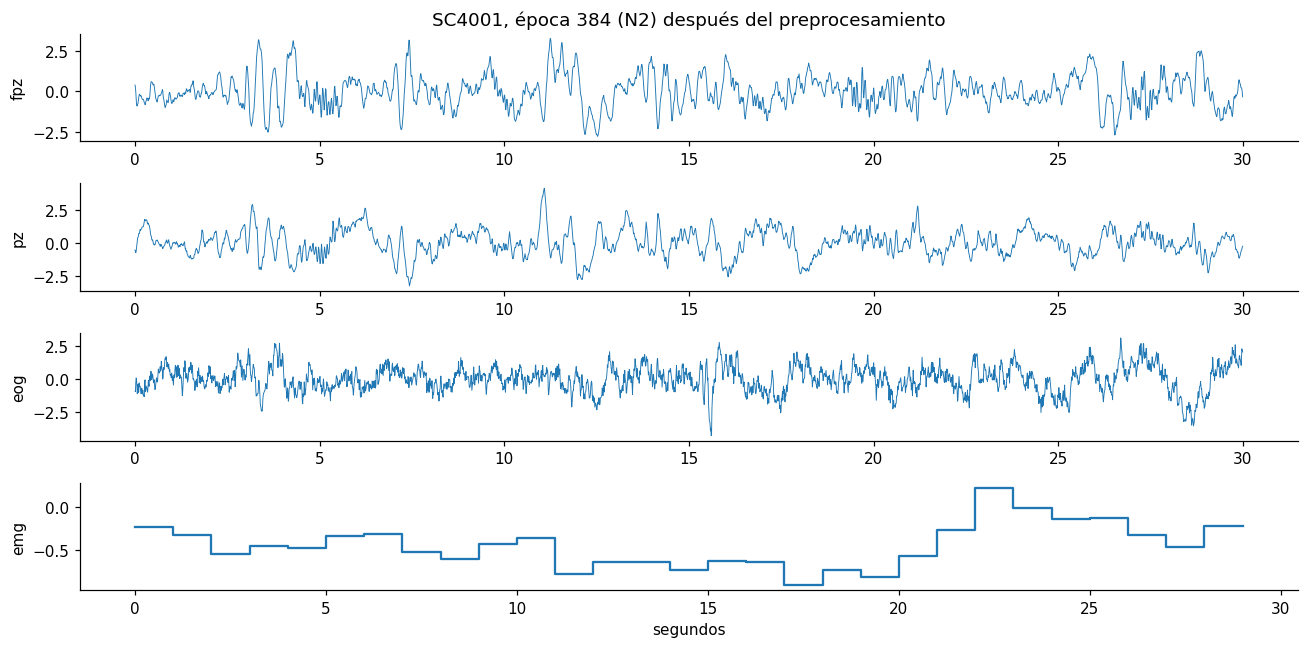

In [4]:
ejemplo = np.load(NOCHES / f"{nights[0][0]}.npz")
e = int(np.where(ejemplo["y"] == 2)[0][100])   # una época de N2
fig, axes = plt.subplots(4, 1, figsize=(12, 6), sharex=False)
for ax, k in zip(axes[:3], ("fpz", "pz", "eog")):
    ax.plot(np.arange(SPE) / FS, ejemplo[k][e].astype(float), lw=0.6)
    ax.set_ylabel(k)
axes[3].step(np.arange(EPOCH), ejemplo["emg"][e], where="post")
axes[3].set_ylabel("emg")
axes[3].set_xlabel("segundos")
axes[0].set_title(f"{nights[0][0]}, época {e} (N2) después del preprocesamiento")
plt.tight_layout()
plt.show()

## 3. La arquitectura, pieza por pieza

Se construye de abajo hacia arriba. Cada pieza se prueba con la época de N2 de arriba y se imprime la forma de lo que sale. Todo esto corre en CPU.

### 3.1 La CNN: 3000 muestras → 94 "pedacitos" de 128 números

Una convolución 1D desliza filtros pequeños sobre la señal. En cada posición multiplica y suma, y el resultado dice cuánto se parece ese trozo de señal al patrón del filtro. Los filtros los aprende la red.

Cada bloque es: convolución sin sesgo → normalización → GELU → Dropout 0.25. El *stride* (salto) va comprimiendo el tiempo:

| Capa | Filtros | Kernel | Stride | Padding | Posiciones de salida |
|---|---|---|---|---|---|
| 1 | 32 | 7 | 2 | 3 | 1500 |
| 2 | 64 | 5 | 2 | 2 | 750 |
| 3 | 128 | 5 | 4 | 2 | 188 |
| 4 | 128 | 3 | 2 | 1 | 94 |

Al final, los 30 s quedan como **94 posiciones (~0.32 s cada una) × 128 filtros**. Cada una de esas 94 columnas es un *token*.

In [5]:
CNN_CHANNELS = (1, 32, 64, 128, 128)
CNN_KERNELS = (7, 5, 5, 3)
CNN_STRIDES = (2, 2, 4, 2)
CNN_PADDINGS = (3, 2, 2, 1)

x = torch.from_numpy(ejemplo["fpz"][e].astype(np.float32))[None, None]   # (batch=1, canal=1, 3000)
print("entrada:", tuple(x.shape))
h = x
for i in range(4):
    conv = nn.Conv1d(CNN_CHANNELS[i], CNN_CHANNELS[i + 1], CNN_KERNELS[i], CNN_STRIDES[i], CNN_PADDINGS[i], bias=False)
    bloque = nn.Sequential(conv, nn.BatchNorm1d(CNN_CHANNELS[i + 1]), nn.GELU(), nn.Dropout(0.25))
    h = bloque(h)
    print(f"bloque {i + 1}: {tuple(h.shape)}   (filtros × posiciones)")

entrada: (1, 1, 3000)
bloque 1: (1, 32, 1500)   (filtros × posiciones)
bloque 2: (1, 64, 750)   (filtros × posiciones)
bloque 3: (1, 128, 188)   (filtros × posiciones)
bloque 4: (1, 128, 94)   (filtros × posiciones)


### 3.2 Codificación posicional

Para el Transformer, los 94 tokens son un conjunto sin orden. Para que sepa en qué momento de la época está cada uno, se le suma a cada token un vector fijo de senos y cosenos que depende de su posición (como en *Attention is All You Need*). No tiene parámetros.

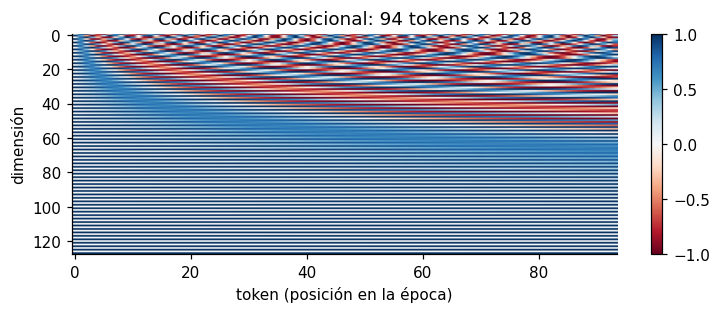

In [6]:
def positional_encoding(n_tokens, d_model):
    pos = torch.arange(n_tokens).unsqueeze(1).float()
    div = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
    pe = torch.zeros(n_tokens, d_model)
    pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
    return pe


plt.figure(figsize=(8, 2.6))
plt.imshow(positional_encoding(94, 128).T, aspect="auto", cmap="RdBu")
plt.xlabel("token (posición en la época)")
plt.ylabel("dimensión")
plt.title("Codificación posicional: 94 tokens × 128")
plt.colorbar()
plt.show()

### 3.3 Una capa de Transformer (pre-norm)

Cada token "pregunta" a los otros 93 qué vieron, y arma una mezcla ponderada de sus respuestas: es la **atención**, con 4 cabezas de 32 dimensiones. Así un token puede saber que en otro momento de la época hubo un huso o un complejo K. Después, una red pequeña procesa cada token (128 → 256 → 128).

Las dos partes llevan **conexión residual** (se suma la entrada) y **LayerNorm antes** de cada una (*pre-norm*), lo que hace el entrenamiento más estable. La salida tiene el mismo tamaño que la entrada: 94 × 128.

In [7]:
class PreNormLayer(nn.Module):
    def __init__(self, d_model, nhead, d_ff, dropout):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.ff = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Dropout(dropout),
                                nn.Linear(d_ff, d_model), nn.Dropout(dropout))

    def forward(self, x, need_weights=False):
        h = self.norm1(x)
        a, w = self.attn(h, h, h, need_weights=need_weights, average_attn_weights=True)
        x = x + a                         # residual de la atención
        x = x + self.ff(self.norm2(x))    # residual de la red pequeña
        return x, w


tokens = h.transpose(1, 2) + positional_encoding(94, 128)   # (1, 94, 128)
capa = PreNormLayer(128, 4, 256, 0.1)
salida, pesos = capa(tokens, need_weights=True)
print("tokens:", tuple(tokens.shape), "→ salida:", tuple(salida.shape), "| pesos de atención:", tuple(pesos.shape))

tokens: (1, 94, 128) → salida: (1, 94, 128) | pesos de atención: (1, 94, 94)


### 3.4 SleepEffFormer: un clasificador de una época

Con las piezas anteriores se arma un clasificador completo de **una** época (reimplementación propia de SleepEffFormer, Paul et al., 2026):

CNN → + codificación posicional → 2 capas de Transformer → LayerNorm → promedio de los 94 tokens → capa lineal 128 → 5.

Los pesos de las capas lineales se inicializan con Xavier y los de las convoluciones con Kaiming.

In [8]:
class SleepEffFormer(nn.Module):
    def __init__(self, n_classes=5, d_model=128, nhead=4, n_layers=2, d_ff=256,
                 cnn_dropout=0.25, tf_dropout=0.1, head_dropout=0.25):
        super().__init__()
        blocks = []
        for i in range(len(CNN_KERNELS)):
            blocks += [nn.Conv1d(CNN_CHANNELS[i], CNN_CHANNELS[i + 1], CNN_KERNELS[i], CNN_STRIDES[i],
                                 CNN_PADDINGS[i], bias=False),
                       nn.BatchNorm1d(CNN_CHANNELS[i + 1]), nn.GELU(), nn.Dropout(cnn_dropout)]
        self.cnn = nn.Sequential(*blocks)
        with torch.no_grad():
            self.n_tokens = self.cnn(torch.zeros(1, 1, 3000)).shape[-1]  # 94
        self.register_buffer("pe", positional_encoding(self.n_tokens, d_model).unsqueeze(0))
        self.pos_dropout = nn.Dropout(tf_dropout)
        self.layers = nn.ModuleList([PreNormLayer(d_model, nhead, d_ff, tf_dropout) for _ in range(n_layers)])
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Sequential(nn.Dropout(head_dropout), nn.Linear(d_model, n_classes))
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Conv1d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")

    def forward(self, x):
        h = self.cnn(x).transpose(1, 2)        # (B, 94, 128)
        h = self.pos_dropout(h + self.pe)
        for layer in self.layers:
            h, _ = layer(h)
        return self.head(self.norm(h).mean(1))  # promedio de los 94 tokens -> 5 logits


sef = SleepEffFormer().eval()
print("parámetros:", f"{sum(p.numel() for p in sef.parameters()):,}", "| logits:", tuple(sef(x).shape))

parámetros: 367,141 | logits: (1, 5)


### 3.5 El codificador de época

El modelo B no usa la cabeza de clasificación de SleepEffFormer. Usa lo de antes: **cada época queda resumida en un vector de 128** (el promedio de los 94 tokens).

Hay un cambio: **GroupNorm en lugar de BatchNorm** en la CNN. El mismo codificador procesa Fpz-Cz, Pz-Oz y EOG, que tienen estadísticas distintas, y cada lote mezcla una proporción distinta de canales. Con BatchNorm, las estadísticas acumuladas durante el entrenamiento no corresponden a ninguna combinación real, y el modelo rendía mucho peor al predecir que al entrenar. GroupNorm normaliza cada época por sí sola.

El codificador se arma construyendo un SleepEffFormer completo y tomando sus partes. Así la inicialización aleatoria es exactamente la misma con la que se obtuvieron los resultados del proyecto.

In [9]:
class EpochEncoder(nn.Module):
    """CNN + Transformer de SleepEffFormer, sin la cabeza: (N, 3000) -> (N, 128)."""

    def __init__(self):
        super().__init__()
        base = SleepEffFormer()
        for i, mod in enumerate(base.cnn):
            if isinstance(mod, nn.BatchNorm1d):
                base.cnn[i] = nn.GroupNorm(8, mod.num_features)
        self.cnn, self.pos_dropout, self.layers, self.norm = base.cnn, base.pos_dropout, base.layers, base.norm
        self.register_buffer("pe", base.pe)

    def forward(self, x):
        h = self.cnn(x.unsqueeze(1)).transpose(1, 2)
        h = self.pos_dropout(h + self.pe)
        for layer in self.layers:
            h, _ = layer(h)
        return self.norm(h).mean(1)


codificador = EpochEncoder().eval()
print("una época (1, 3000) →", tuple(codificador(x[:, 0]).shape))

una época (1, 3000) → (1, 128)


### 3.6 El modelo completo

Entrada de un trozo de **L = 80 épocas seguidas** de la misma noche:
- `sig`: (B, 80, 3, 3000), con Fpz-Cz, Pz-Oz y EOG. Los canales ausentes pueden ir en cero: no se usan.
- `emg`: (B, 80, 30), la envolvente del EMG.
- `mask`: (B, 4), qué modalidades hay: [fpz, pz, eog, emg].

Pasos:
1. **Codificador de época** (el mismo para los 3 canales de 100 Hz) → 128 por época y canal. A cada uno se le suma un **vector aprendido que dice de qué canal viene**.
2. **EMG:** una red pequeña 30 → 64 → 128.
3. **Fusión:** promedio de las modalidades **presentes** (las ausentes no entran) + la máscara de 4 números, para que la red sepa qué combinación está viendo. Una capa lineal 132 → 128.
4. **Transformer entre épocas** sobre las 80 épocas: se suma la codificación posicional de la sección 3.2 (ahora la posición es la de la época dentro del trozo) y se aplican 2 capas `PreNormLayer` como las de la sección 3.3 (4 cabezas, 128 → 256 → 128). Cada época arma una mezcla de lo que vieron las otras 79, sin importar qué tan lejos estén. Al final, LayerNorm.
5. **Capa lineal 128 → 5** para cada una de las 80 épocas.

In [10]:
class ModeloB(nn.Module):
    def __init__(self, d=128, n_classes=5, dropout=0.3, seq_layers=2, seq_heads=4, seq_ff=256, seq_dropout=0.1,
                 max_len=512):
        super().__init__()
        self.d = d
        self.encoder = EpochEncoder()
        self.channel_emb = nn.Parameter(torch.zeros(3, d))          # un vector por canal (fpz, pz, eog)
        self.emg = nn.Sequential(nn.Linear(30, 64), nn.GELU(), nn.Linear(64, d))
        self.fuse = nn.Linear(d + 4, d)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("seq_pe", positional_encoding(max_len, d))   # posición de la época en el trozo
        self.seq_layers = nn.ModuleList([PreNormLayer(d, seq_heads, seq_ff, seq_dropout) for _ in range(seq_layers)])
        self.seq_norm = nn.LayerNorm(d)
        self.out = nn.Linear(d, n_classes)

    def forward(self, sig, emg, mask):
        b, length = sig.shape[:2]
        feats = sig.new_zeros(b, length, 4, self.d, dtype=torch.float32)
        for c in range(3):  # solo se codifican los canales presentes
            sel = mask[:, c]
            if sel.any():
                x = sig[sel][:, :, c].reshape(-1, sig.shape[-1])
                feats[sel, :, c] = (self.encoder(x).float() + self.channel_emb[c]).reshape(int(sel.sum()), length, self.d)
        sel = mask[:, 3]
        if sel.any():
            feats[sel, :, 3] = self.emg(emg[sel]).float()
        m = mask.float()[:, None, :, None]
        pooled = (feats * m).sum(2) / m.sum(2).clamp(min=1.0)              # promedio de los presentes
        h = self.fuse(torch.cat([pooled, mask.float()[:, None, :].expand(b, length, 4)], -1))
        h = self.dropout(F.gelu(h)) + self.seq_pe[:length]
        for layer in self.seq_layers:   # cada época mira a todas las del trozo
            h, _ = layer(h)
        return self.out(self.dropout(self.seq_norm(h)))


modelo = ModeloB().eval()
L = 80
sig = torch.from_numpy(np.stack([ejemplo[k][e:e + L] for k in ("fpz", "pz", "eog")], 1).astype(np.float32))[None]
emg = torch.from_numpy(ejemplo["emg"][e:e + L])[None]
mask = torch.tensor([mascara("fpz_eog")])
print("sig", tuple(sig.shape), "· emg", tuple(emg.shape), "· máscara", mask.tolist(), "→", tuple(modelo(sig, emg, mask).shape))
print("parámetros:", f"{sum(p.numel() for p in modelo.parameters() if p.requires_grad):,}")

sig (1, 80, 3, 3000) · emg (1, 80, 30) · máscara [[True, False, True, False]] → (1, 80, 5)
parámetros: 660,069


## 4. Cómo se arman los datos para entrenar

- **Trozos de 80 épocas.** En cada pasada (una vuelta completa por los datos), cada noche se corta en trozos de 80 épocas seguidas que no se pisan, empezando en un **desfase al azar entre 0 y 79**. Así, una época que en una pasada quedó en el borde de un trozo, en otra queda en el medio. Los trozos de todas las noches se **barajan** y entran de a **2** (un paso de entrenamiento). Son 160 épocas por paso, las mismas que en la versión original (8 × 20), para que el número de pasos por pasada, la tasa de aprendizaje y la EMA se comporten igual.
- **Canales al azar.** A cada trozo se le sortea una de las 12 combinaciones de canales. Fpz-Cz solo y Pz-Oz solo tienen el doble de probabilidad, porque son los casos más difíciles.
- **Pesos por clase:** balanceado^0.44, igual que en el paso 1.

Las noches se cargan una sola vez en la memoria del dispositivo (la señal en float16).

In [11]:
HP = dict(seq_len=80, batch=2, lr=3e-4, weight_decay=1e-4, max_epochs=100, min_epochs=40, patience=15, clip=1.0,
          ema=0.999, alpha=0.44, stride=40)
SAMPLE_WEIGHT = {c: (2.0 if c in ("fpz", "pz") else 1.0) for c in CONFIGS}
VAL_CONFIGS = ("fpz", "pz", "eeg2_eog_emg")


class Nights:
    """Noches concatenadas en tensores del dispositivo, con el inicio y el largo de cada una."""

    def __init__(self, data, nights, device):
        self.nights = list(nights)
        lengths = [len(data[n]["y"]) for n in self.nights]
        self.start = np.concatenate([[0], np.cumsum(lengths)[:-1]]).astype(np.int64)
        self.length = np.array(lengths)
        self.sig = torch.from_numpy(np.concatenate(
            [np.stack([data[n][k] for k in ("fpz", "pz", "eog")], 1) for n in self.nights])).to(device)
        self.emg = torch.from_numpy(np.concatenate([data[n]["emg"] for n in self.nights])).to(device)
        self.y = torch.from_numpy(np.concatenate([data[n]["y"] for n in self.nights])).to(device)


def class_weights(y, alpha):
    counts = np.bincount(y, minlength=5).astype(float)
    return (len(y) / (5 * np.maximum(counts, 1))) ** alpha


def train_windows(nd, rng, L):
    """Inicios de los trozos de una pasada: un desfase al azar por noche, trozos sin traslape, barajados."""
    starts = []
    for s, n in zip(nd.start, nd.length):
        off = int(rng.integers(0, L)) if n > L else 0
        starts += [s + o for o in range(off, max(n - L, 0) + 1, L)]
    return rng.permutation(np.array(starts, dtype=np.int64))


p_cfg = np.array([SAMPLE_WEIGHT[c] for c in CONFIGS])
print("probabilidad de cada combinación:", {c: round(float(p), 3) for c, p in zip(CONFIGS, p_cfg / p_cfg.sum())})

probabilidad de cada combinación: {'fpz': 0.143, 'pz': 0.143, 'eeg2': 0.071, 'fpz_eog': 0.071, 'pz_eog': 0.071, 'eeg2_eog': 0.071, 'fpz_emg': 0.071, 'pz_emg': 0.071, 'eeg2_emg': 0.071, 'fpz_eog_emg': 0.071, 'pz_eog_emg': 0.071, 'eeg2_eog_emg': 0.071}


## 5. Entrenamiento

- **Pérdida:** entropía cruzada con pesos por clase, sobre las 160 épocas del paso (2 trozos × 80).
- **Optimizador:** AdamW (tasa 3·10⁻⁴, *weight decay* 10⁻⁴). La tasa baja como un coseno hasta 10⁻⁶ a lo largo de 100 pasadas. Recorte del gradiente a norma 1.0 y precisión mixta (float16) en GPU.
- **EMA:** se mantiene un promedio exponencial de los pesos (0.999). Es más estable que los pesos del último paso, y es lo que se evalúa y se guarda.
- **Validación en cada pasada** con 3 combinaciones: Fpz-Cz solo, Pz-Oz solo y los 4 canales. El puntaje es el promedio de sus MF1.
- **Parada:** como máximo 100 pasadas. Para si pasan 15 sin mejorar el puntaje, pero nunca antes de la 40. Se queda con los pesos (EMA) de la mejor pasada.

In [12]:
def compute_metrics(y_true, y_pred):
    f1 = f1_score(y_true, y_pred, labels=range(5), average=None, zero_division=0)
    return {"acc": accuracy_score(y_true, y_pred), "mf1": f1.mean(), "kappa": cohen_kappa_score(y_true, y_pred),
            **{f"f1_{s}": v for s, v in zip(ESTADIOS, f1)},
            "confusion": confusion_matrix(y_true, y_pred, labels=range(5))}


class EMA:
    """Promedio exponencial de los pesos del modelo."""

    def __init__(self, model, decay):
        self.decay, self.steps = decay, 0
        self.model = copy.deepcopy(model).eval()
        for p in self.model.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        self.steps += 1
        w = 1 - min(self.decay, (1 + self.steps) / (10 + self.steps))   # al inicio sigue al modelo más de cerca
        for e, m in zip(self.model.parameters(), model.parameters()):
            e.lerp_(m.detach(), w)
        for e, m in zip(self.model.buffers(), model.buffers()):
            if e.dtype.is_floating_point:
                e.lerp_(m, w)
            else:
                e.copy_(m)


def _amp(device):
    return torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda")


@torch.no_grad()
def predict_night(model, nd, i, cfg, device, L=None, stride=None, batch=16):
    """Probabilidades (n, 5) de la noche i con la combinación cfg (ver sección 6)."""
    model.eval()
    L, stride = L or HP["seq_len"], stride or HP["stride"]
    s, n = int(nd.start[i]), int(nd.length[i])
    L = min(L, n)
    starts = list(range(0, n - L + 1, stride))
    if starts[-1] != n - L:
        starts.append(n - L)
    acc = torch.zeros(n, 5, device=device)
    cnt = torch.zeros(n, 1, device=device)
    mask1 = torch.tensor(mascara(cfg), device=device)
    for j in range(0, len(starts), batch):
        st = torch.tensor(starts[j:j + batch], device=device)
        idx = s + st[:, None] + torch.arange(L, device=device)
        with _amp(device):
            logits = model(nd.sig[idx].float() if device.type != "cuda" else nd.sig[idx], nd.emg[idx],
                           mask1.expand(len(st), 4))
        p = torch.softmax(logits.float(), -1)
        loc = st[:, None] + torch.arange(L, device=device)
        acc.index_add_(0, loc.reshape(-1), p.reshape(-1, 5))
        cnt.index_add_(0, loc.reshape(-1), torch.ones(loc.numel(), 1, device=device))
    return (acc / cnt).cpu().numpy()


def evaluate(model, nd, configs, device):
    y = nd.y.cpu().numpy()
    out = {}
    for cfg in configs:
        p = np.concatenate([predict_night(model, nd, i, cfg, device) for i in range(len(nd.nights))])
        out[cfg] = compute_metrics(y, p.argmax(1))
    return out


def fit(train, val_nd, log_path, device, seed=SEED, max_epochs=None):
    """Entrena y devuelve (mejor pasada, pesos EMA de la mejor pasada)."""
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    max_epochs = max_epochs or HP["max_epochs"]
    L, bs = HP["seq_len"], HP["batch"]

    model = ModeloB().to(device)
    ema = EMA(model, HP["ema"])
    opt = torch.optim.AdamW(model.parameters(), lr=HP["lr"], weight_decay=HP["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=HP["max_epochs"], eta_min=1e-6)
    w = torch.tensor(class_weights(train.y.cpu().numpy(), HP["alpha"]), dtype=torch.float32, device=device)
    criterion = nn.CrossEntropyLoss(weight=w)
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")
    cfg_names = list(CONFIGS)
    p = np.array([SAMPLE_WEIGHT[c] for c in cfg_names])
    p = p / p.sum()
    masks = torch.tensor([mascara(c) for c in cfg_names], device=device)

    best, best_state = {"score": -1.0, "epoch": 0}, None
    with open(log_path, "w", newline="") as f:
        wr = csv.writer(f)
        wr.writerow(["epoch", "train_loss", *[f"val_mf1_{c}" for c in VAL_CONFIGS], "val_f1_N1_fpz", "score", "lr", "seconds"])
        for epoch in range(1, max_epochs + 1):
            t0 = time.perf_counter()
            model.train()
            starts = train_windows(train, rng, L)
            total, nb = 0.0, 0
            for j in range(0, len(starts), bs):
                st = torch.from_numpy(starts[j:j + bs]).to(device)
                idx = st[:, None] + torch.arange(L, device=device)
                mk = masks[torch.from_numpy(rng.choice(len(cfg_names), size=len(st), p=p)).to(device)]
                sig = train.sig[idx] if device.type == "cuda" else train.sig[idx].float()
                with _amp(device):
                    logits = model(sig, train.emg[idx], mk)
                    loss = criterion(logits.float().reshape(-1, 5), train.y[idx].reshape(-1))
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(model.parameters(), HP["clip"])
                scaler.step(opt)
                scaler.update()
                ema.update(model)
                total += loss.item()
                nb += 1
            lr = opt.param_groups[0]["lr"]
            sched.step()

            val = evaluate(ema.model, val_nd, VAL_CONFIGS, device)
            score = float(np.mean([val[c]["mf1"] for c in VAL_CONFIGS]))
            wr.writerow([epoch, total / nb, *[val[c]["mf1"] for c in VAL_CONFIGS], val["fpz"]["f1_N1"], score, lr,
                         round(time.perf_counter() - t0, 1)])
            f.flush()
            if score > best["score"]:
                best = {"score": score, "epoch": epoch}
                best_state = copy.deepcopy(ema.model.state_dict())
            if epoch >= HP["min_epochs"] and epoch - best["epoch"] >= HP["patience"]:
                break
    return best, best_state

## 6. Predicción de una noche

Al predecir no hay azar. La noche se recorre con ventanas de 80 épocas que avanzan **de 40 en 40**, así que cada época cae en dos ventanas: en una queda cerca del borde (le falta contexto de un lado) y en la otra en el medio. Se **promedian** las probabilidades de las dos (`predict_night`, en la celda anterior).

Se predice la noche completa con cada una de las 12 combinaciones, apagando los canales ausentes con la máscara.

## 7. Los 6 entrenamientos

Son los **5 folds** de `particiones.json`, que dan las predicciones fuera de fold que necesita el meta-modelo, y el **modelo final**, que se entrena con los 62 sujetos de desarrollo y predice el test de 16.

`run_fold` hace un entrenamiento completo: carga las noches, entrena, predice las noches de test del fold con las 12 combinaciones y guarda el resultado en `paso_3_meta_model/entradas/paso_2_transformer/<fold>.npz`.

In [13]:
NOMBRES = ["fold_0"] if PRUEBA else ["final", "fold_0", "fold_1", "fold_2", "fold_3", "fold_4"]


def fold_spec(name):
    return particion["final"] if name == "final" else particion["folds"][int(name.split("_")[1])]


def listo(name):
    return (SALIDA / f"{name}.npz").exists()


def run_fold(name):
    fold = fold_spec(name)
    device = torch.device(DISPOSITIVO)
    available = sorted(p.stem for p in NOCHES.glob("SC4*.npz"))
    of = lambda subjects: [n for n in available if int(n[3:5]) in set(subjects)]  # noqa: E731
    tr, va, te = of(fold["train"]), of(fold["val"]), of(fold["test"])
    if PRUEBA:
        tr, va, te = tr[:6], va[:2], te[:2]
    t0 = time.perf_counter()
    data = {n: dict(np.load(NOCHES / f"{n}.npz")) for n in tr + va}
    train_nd, val_nd = Nights(data, tr, device), Nights(data, va, device)
    best, best_state = fit(train_nd, val_nd, LOGS / f"{name}_log.csv", device, max_epochs=2 if PRUEBA else None)
    del train_nd, val_nd, data

    model = ModeloB().to(device)
    model.load_state_dict(best_state)
    test_data = {n: dict(np.load(NOCHES / f"{n}.npz")) for n in te}
    test_nd = Nights(test_data, te, device)
    arr = {}
    for cfg in CONFIGS:
        for i, n in enumerate(te):
            arr[f"{cfg}__{n}"] = predict_night(model, test_nd, i, cfg, device).astype(np.float32)
    for n in te:
        arr[f"y__{n}"], arr[f"pos__{n}"] = test_data[n]["y"], test_data[n]["pos"]
    np.savez_compressed(SALIDA / f"{name}.npz", **arr)
    (LOGS / f"{name}_resumen.json").write_text(json.dumps(
        {"mejor_pasada": best["epoch"], "puntaje_val": best["score"], "minutos": round((time.perf_counter() - t0) / 60, 1)}))

**En paralelo, sin salir del notebook.** En Linux (Colab), `multiprocessing` con `fork` crea copias del proceso del notebook. Cada copia ya tiene definidas todas las funciones de arriba y entrena un fold por su cuenta en la misma GPU.

Para que funcione, este proceso principal no debe usar la GPU antes de crear las copias; por eso todo lo anterior corrió en CPU. Cada entrenamiento fija su semilla al empezar, así que el resultado es el mismo en paralelo que uno tras otro.

La tabla se actualiza cada minuto:
- **val fpz / pz / 4ch:** MF1 de validación con esos canales;
- **mejor:** su promedio, el puntaje del early stopping.

Si se interrumpe esta celda, los entrenamientos siguen corriendo; al volver a ejecutarla, retoma la tabla. Con `EN_PARALELO = 1` corren uno tras otro en este mismo proceso, lo que sirve en cualquier sistema operativo.

In [14]:
def _en_proceso_aparte(name):
    log = open(LOGS / f"{name}.out", "a")
    sys.stdout = sys.stderr = log
    # El proceso principal ya hizo cálculos en CPU (sección 3) y OpenMP no es seguro después de fork:
    # la copia usa un solo hilo de CPU. El trabajo pesado va en la GPU.
    torch.set_num_threads(1)
    run_fold(name)


def avance(name):
    try:
        lg = pd.read_csv(LOGS / f"{name}_log.csv")
    except (FileNotFoundError, pd.errors.EmptyDataError):
        return {}
    if lg.empty:
        return {}
    u = lg.iloc[-1]
    return {"pasada": int(u.epoch), "val fpz": round(float(u.val_mf1_fpz), 3), "val pz": round(float(u.val_mf1_pz), 3),
            "val 4ch": round(float(u.val_mf1_eeg2_eog_emg), 3), "mejor": round(float(lg.score.max()), 3),
            "mejor pasada": int(lg.score.idxmax()) + 1, "s/pasada": int(round(lg.seconds.tail(3).mean()))}


def vivo(pid):
    try:
        os.kill(pid, 0)
        return True
    except OSError:
        return False


t0 = time.time()
if EN_PARALELO == 1:
    for name in NOMBRES:
        if not listo(name):
            run_fold(name)
            print(name, "listo", avance(name), f"({(time.time() - t0) / 60:.0f} min)")
else:
    ctx = mp.get_context("fork")
    corriendo, fallidos = {}, set()
    for name in NOMBRES:  # entrenamientos que siguen vivos de una ejecución anterior de esta celda
        pid_file = LOGS / f"{name}.pid"
        if pid_file.exists() and not listo(name) and vivo(int(pid_file.read_text())):
            corriendo[name] = int(pid_file.read_text())
    while True:
        mp.active_children()  # recoge los procesos que ya terminaron
        for name, pid in list(corriendo.items()):
            if listo(name) or not vivo(pid):
                corriendo.pop(name)
                if not listo(name):
                    fallidos.add(name)
        pendientes = [n for n in NOMBRES if not listo(n) and n not in corriendo and n not in fallidos]
        while pendientes and len(corriendo) < EN_PARALELO:
            name = pendientes.pop(0)
            proc = ctx.Process(target=_en_proceso_aparte, args=(name,))
            proc.start()
            (LOGS / f"{name}.pid").write_text(str(proc.pid))
            corriendo[name] = proc.pid
        estado = lambda n: "listo" if listo(n) else "corriendo" if n in corriendo else "ERROR" if n in fallidos else "en cola"  # noqa: E731
        clear_output(wait=True)
        print(f"{(time.time() - t0) / 60:.0f} min · listos {sum(listo(n) for n in NOMBRES)}/{len(NOMBRES)}")
        display(pd.DataFrame([{"entrenamiento": n, "estado": estado(n), **avance(n)} for n in NOMBRES]).fillna(""))
        for name in sorted(fallidos):
            print(f"\nERROR en {name}:\n" + "".join(open(LOGS / f"{name}.out").readlines()[-15:]))
        if not corriendo and not [n for n in NOMBRES if not listo(n) and n not in fallidos]:
            break
        time.sleep(10 if PRUEBA else 60)
print("Terminado.")

123 min · listos 6/6


,entrenamiento,estado,pasada,val fpz,val pz,val 4ch,mejor,mejor pasada,s/pasada
0,final,listo,100,0.748,0.739,0.769,0.754,88,32
1,fold_0,listo,100,0.741,0.736,0.763,0.747,96,41
2,fold_1,listo,89,0.781,0.735,0.788,0.773,74,61
3,fold_2,listo,100,0.766,0.715,0.788,0.758,89,33
4,fold_3,listo,90,0.796,0.782,0.823,0.802,75,60
5,fold_4,listo,50,0.810,0.736,0.816,0.789,35,75


Terminado.


## 8. Resultados

### 8.1 Entrenamiento

En la tesis, con la BiLSTM de 20 épocas, las mejores pasadas fueron 63, 59, 59, 90 y 44 en los folds y 94 en el modelo final. Varios entrenamientos llegaron a la pasada 100 todavía mejorando un poco.

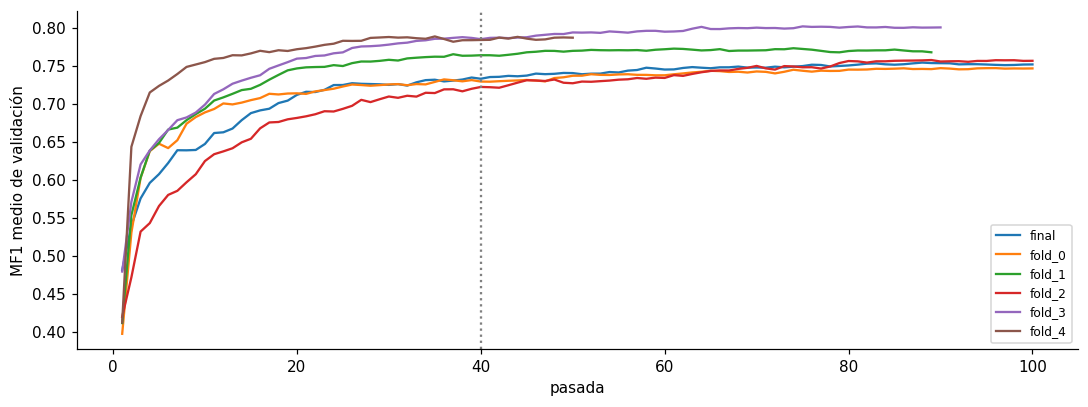

,pasadas,mejor pasada,puntaje de validación
entrenamiento,,,
final,100,88,0.754
fold_0,100,96,0.747
fold_1,89,74,0.773
fold_2,100,89,0.758
fold_3,90,75,0.802
fold_4,50,35,0.789


In [ ]:
fig, ax = plt.subplots(figsize=(10, 3.8))
filas = []
for name in NOMBRES:
    lg = pd.read_csv(LOGS / f"{name}_log.csv")
    r = json.loads((LOGS / f"{name}_resumen.json").read_text())
    ax.plot(lg.epoch, lg.score, label=name)
    filas.append({"entrenamiento": name, "pasadas": len(lg), "mejor pasada": r["mejor_pasada"],
                  "puntaje de validación": round(r["puntaje_val"], 3)})
ax.axvline(HP["min_epochs"], ls=":", color="gray")
ax.set_xlabel("pasada")
ax.set_ylabel("MF1 medio de validación")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
pd.DataFrame(filas).set_index("entrenamiento")

### 8.2 Validación cruzada (62 sujetos)

Las noches de test de los 5 folds juntas son las predicciones **fuera de fold**: cada persona la predijo un modelo que no la vio. La columna de la derecha es el MF1 de la versión original (BiLSTM de 20 épocas) en la tesis, para comparar.

In [16]:
def load_fold_preds(name):
    """combinación -> noche -> (y, probabilidades)"""
    z = np.load(SALIDA / f"{name}.npz")
    out = {}
    for k in z.files:
        if k.startswith(("y__", "pos__")):
            continue
        cfg, n = k.split("__")
        out.setdefault(cfg, {})[n] = (z[f"y__{n}"], z[k])
    return out


def metrics_of(preds):
    y = np.concatenate([y for y, _ in preds.values()])
    p = np.concatenate([p.argmax(1) for _, p in preds.values()])
    return compute_metrics(y, p)


oof = {c: {} for c in CONFIGS}
for name in [n for n in NOMBRES if n != "final"]:
    for c, d in load_fold_preds(name).items():
        oof[c].update(d)
TESIS = {"fpz": 0.754, "pz": 0.721, "fpz_eog": 0.780, "eeg2_eog": 0.784, "eeg2_eog_emg": 0.785}
filas = []
for c in CONFIGS:
    m = metrics_of(oof[c])
    filas.append({"combinación": c, "MF1": m["mf1"], "κ": m["kappa"], "acc": m["acc"], "F1 N1": m["f1_N1"],
                  "BiLSTM 20 (MF1)": TESIS.get(c, "")})
pd.DataFrame(filas).set_index("combinación").style.format(precision=3)

,MF1,κ,acc,F1 N1,BiLSTM 20 (MF1)
combinación,,,,,
fpz,0.766,0.754,0.820,0.545,0.754
pz,0.737,0.728,0.801,0.515,0.721
eeg2,0.783,0.777,0.837,0.569,
fpz_eog,0.780,0.767,0.829,0.559,0.780
pz_eog,0.770,0.761,0.825,0.554,
eeg2_eog,0.790,0.784,0.842,0.578,0.784
fpz_emg,0.772,0.760,0.824,0.550,
pz_emg,0.740,0.731,0.802,0.517,
eeg2_emg,0.784,0.778,0.837,0.571,


## 9. Matrices de confusión

Validación cruzada (62 sujetos) y test (16 sujetos, modelo final), solo con Fpz-Cz y con los 4 canales. Cada fila es el estadio real y suma 100 %.

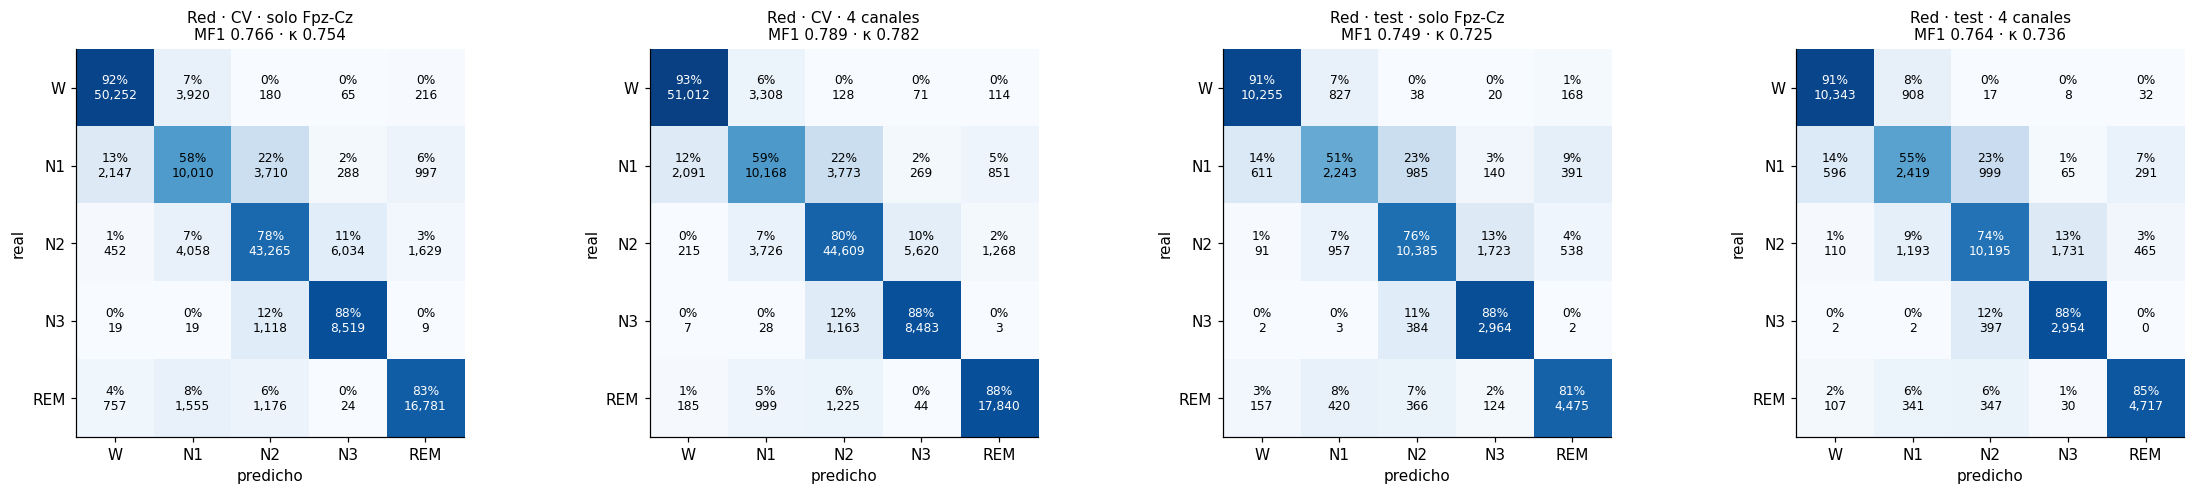

In [17]:
def plot_confusion(cm, title, ax):
    cm = np.asarray(cm)
    cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{cmn[i, j]:.0%}\n{cm[i, j]:,}", ha="center", va="center", fontsize=8,
                    color="white" if cmn[i, j] > 0.6 else "black")
    ax.set_xticks(range(5), ESTADIOS)
    ax.set_yticks(range(5), ESTADIOS)
    ax.set_xlabel("predicho")
    ax.set_ylabel("real")
    ax.set_title(title, fontsize=10)


test = load_fold_preds("final") if "final" in NOMBRES else None
fig, axes = plt.subplots(1, 4 if test else 2, figsize=(21 if test else 11, 4.6))
paneles = [(oof, "CV"), (test, "test")] if test else [(oof, "CV")]
k = 0
for preds, nombre_split in paneles:
    for c, nombre in [("fpz", "solo Fpz-Cz"), ("eeg2_eog_emg", "4 canales")]:
        m = metrics_of(preds[c])
        plot_confusion(m["confusion"], f"Red · {nombre_split} · {nombre}\nMF1 {m['mf1']:.3f} · κ {m['kappa']:.3f}", axes[k])
        k += 1
plt.tight_layout()
plt.show()

En la tesis, la versión original de la red (BiLSTM de 20 épocas) quedó un poco por debajo del XGBoost en MF1 (−0.01 a −0.02 en la CV), pero **le ganó en N1** en todas las combinaciones. Además se equivocaba en épocas distintas: compartía solo el 59–65 % de los errores del XGBoost. Eso es lo que aprovecha el meta-modelo del paso 3, que dice cuánto comparte esta variante.